# 02 · NYC FloodNet – street flood sensors

**Utility for the City Brain: high** · Domain: flood · Incident types: `flood`

> 3,526 real street-flood events in New York with their full depth curve (1-minute steps): how fast water rises, how deep it gets and how long it takes to drain.

| | |
|---|---|
| **Source** | NYC Open Data: events `aq7i-eu5q`, sensors `kb2e-tjy3` (FloodNet project) |
| **Licence** | NYC Open Data, open |
| **In this repo** | Full files: `data/flood/floodnet/events.csv`, `sensors.csv` |
| **Get it** | https://data.cityofnewyork.us/resource/aq7i-eu5q.csv |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

`events.csv`: one row per flood event. Key columns: sensor name and id, flood start / end (GMT), **maximum depth (inches)**, time to max depth, time to drain, durations above 4 / 12 / 24 in, and two lists: **depth values** and their **timestamps** (seconds from start).

`sensors.csv`: one row per sensor with position, borough, install date, and whether it's **tidally influenced**.

In [2]:
ev = pd.read_csv(path('flood/floodnet/events.csv'))
se = pd.read_csv(path('flood/floodnet/sensors.csv'))
ev.columns = ['sensor', 'sensor_id', 'start', 'end', 'max_in', 'to_peak_min', 'drain_min', 'dur_min',
              'over4_min', 'over12_min', 'over24_min', 'depths', 'secs']
ev['start'] = pd.to_datetime(ev.start, format='%m/%d/%Y %I:%M:%S %p')
print(f"{len(ev):,} events from {ev.sensor_id.nunique()} sensors, {ev.start.min():%b %Y} to {ev.start.max():%b %Y}; {len(se)} sensors listed")
ev.drop(columns=['depths', 'secs']).head()

3,526 events from 319 sensors, Nov 2020 to Oct 2026; 491 sensors listed


,sensor,sensor_id,start,end,max_in,to_peak_min,drain_min,dur_min,over4_min,over12_min,over24_min
0,Q - Beach 84 St,Q-beach-84-st-0me680,2023-10-30 12:00:39,10/30/2023 04:38:19 PM,17.72,133.86,143.81,277.66,211.41,103.6,0.0
1,BX - 1st St/Avenue A,BX-1st-st-avenue-a-1zby90,2025-04-26 23:17:20,04/27/2025 11:55:34 AM,6.18,27.95,730.29,758.24,132.81,0.0,0.0
2,Q - Beach 35 St/Beach Channel Dr,Q-beach-35-st-beach-channel-dr-1oeug0,2024-02-09 11:41:01,02/09/2024 01:20:57 PM,5.31,54.51,45.43,99.94,45.09,0.0,0.0
3,BX - Tibbett Ave/W 234th St,BX-w-234th-st-tibbett-ave-2cakho,2025-08-20 21:05:19,08/21/2025 12:46:19 AM,1.18,80.00,141.00,221.00,0.00,0.0,0.0
4,Q - Davenport Ct 1,Q-davenport-ct-1-07zks0,2024-01-10 00:39:25,01/10/2024 02:30:40 AM,2.09,59.82,51.43,111.25,0.00,0.0,0.0


## 2. How floods behave

In [3]:
ev['rise_in_per_min'] = ev.max_in / ev.to_peak_min.replace(0, np.nan)
q = ev[['max_in', 'to_peak_min', 'rise_in_per_min', 'drain_min', 'dur_min']].quantile([.1, .5, .9]).round(2)
q.index = ['10 %', '50 %', '90 %']; q

,max_in,to_peak_min,rise_in_per_min,drain_min,dur_min
10 %,0.91,6.00,0.03,12.00,19.95
50 %,3.46,36.86,0.10,53.56,111.20
90 %,11.06,118.98,0.42,195.64,284.23


In [4]:
tidal = ev.merge(se[['Sensor ID', 'Tidally Influenced']], left_on='sensor_id', right_on='Sensor ID', how='left')
print('Share of events from tidally influenced sensors:', round((tidal['Tidally Influenced'] == 'Yes').mean() * 100), '%')
print('Share of events that never exceed 1 inch:', round((ev.max_in < 1).mean() * 100), '%')

Share of events from tidally influenced sensors: 67 %
Share of events that never exceed 1 inch: 12 %


## 3. Real depth curves (Hurricane Ida night, 1 Sep 2021, Gowanus, Brooklyn)

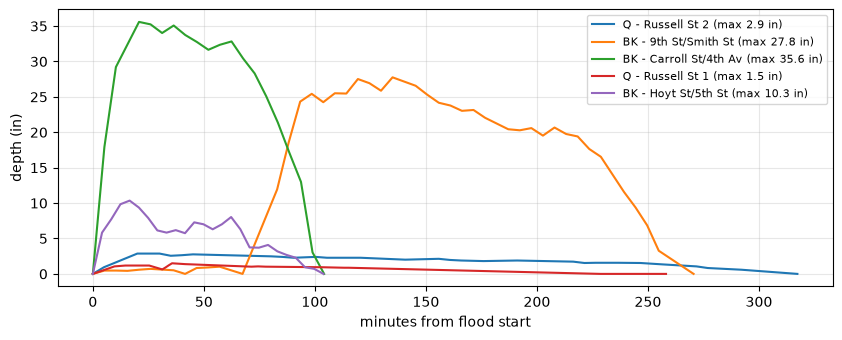

,sensor,start,max_in,to_peak_min,drain_min
409,Q - Russell St 2,2021-09-02 01:51:03,2.87,20.03,297.30
561,BK - 9th St/Smith St,2021-09-02 00:11:58,27.76,134.99,135.58
1568,BK - Carroll St/4th Av,2021-09-02 01:27:16,35.59,20.80,83.38
1776,Q - Russell St 1,2021-09-02 02:03:01,1.50,35.68,222.46
1950,BK - Hoyt St/5th St,2021-09-02 01:24:41,10.35,16.59,87.29


In [5]:
ida = ev[(ev.start >= '2021-09-01 22:00') & (ev.start <= '2021-09-02 04:00')]   # GMT
fig, ax = plt.subplots()
for _, r in ida.iterrows():
    y = json.loads(r.depths); t = np.array(json.loads(r.secs)) / 60
    ax.plot(t, y, label=f"{r.sensor} (max {r.max_in:.1f} in)")
ax.set_xlabel('minutes from flood start'); ax.set_ylabel('depth (in)'); ax.legend(fontsize=8); plt.show()
ida[['sensor', 'start', 'max_in', 'to_peak_min', 'drain_min']]

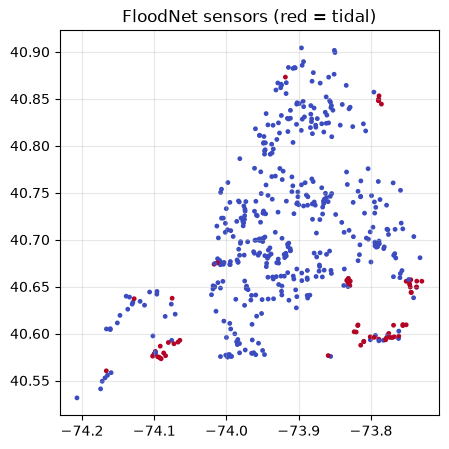

In [6]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(se.Longitude, se.Latitude, s=6, c=(se['Tidally Influenced'] == 'Yes'), cmap='coolwarm')
ax.set_title('FloodNet sensors (red = tidal)'); ax.set_aspect(1.3); plt.show()

## 4. What it means for the City Brain

| Use | How |
|---|---|
| **Detect** | Real rise rates (median ≈ 0.1 in/min, fast ≈ 0.4) for the "abnormal **and rising**" rule; drain times (median ≈ 1 h) for when to **close** a flood incident |
| **Graph** | The 3 Gowanus sensors are < 1 km apart and flood within 75 min: test that the graph links **one incident across neighbouring zones**, not three duplicates |
| **Mock** | Replay real depth curves as `water_level` sensors |
| **Scenarios** | Big flood (35 in), shallow ambiguous water (< 1 in, 12 % of events), tidal floods (predictable, normal) |

**Limits:** only flood events are recorded (no calm baseline: see notebook 03, USGS); street sensors in inches; times in GMT.